<img src="https://tmsearch.onlinepatent.ru/images/4f4/4f4a7d24-030a-42d7-88d7-6bc7ed6066f8.jpg" width="400">

# 🐍 Занятие №8. Python.

**Сегодня в программе:** решаем проект "Анализ резюме на hh.ru":
- исследование структуры данных (первичное знакомство)
- преобразование данных
- EDA (разведывательный анализ)
- очистка данных

In [ ]:
import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 200)

## 1. Исследование структуры данных (знакомство)

- head()
- shape
- info()
- describe()
- *если есть признак даты - смотри границы диапазона

1. Прочитаем данные с помощью библиотеки Pandas.

>PS: перед чтением обратите внимание на разделитель внутри файла.

In [ ]:
file_id = "1nkX-Zc2Mmj94NRITQVptHBdfoe1s-HWf"
url = f"https://drive.google.com/uc?id={file_id}"
gdown.download(url, "resume_database.csv", quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1nkX-Zc2Mmj94NRITQVptHBdfoe1s-HWf
From (redirected): https://drive.google.com/uc?id=1nkX-Zc2Mmj94NRITQVptHBdfoe1s-HWf&confirm=t&uuid=78fda68d-6c44-42ff-973e-3300fe6d2f9d
To: /content/resume_database.csv
100%|██████████| 455M/455M [00:07<00:00, 59.5MB/s]


'resume_database.csv'

In [ ]:
data = pd.read_csv("resume_database.csv", sep=';')
print(data.shape)
data.head()

(44744, 12)


,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к переезду , не готов к командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, вахтовый метод, удаленная работа","Опыт работы 16 лет 10 месяцев Август 2010 — по настоящее время 8 лет 10 месяцев МАОУ ""СОШ № 1 г.Немана"" Системный администратор Обслуживание ПК,установка ПО, ремонт, периферийной техники, Интерне...","МАОУ ""СОШ № 1 г.Немана""",Системный администратор,"Неоконченное высшее образование 2000 Балтийская государственная академия рыбопромыслового флота, Калининград судоводительский, Организация и безопасность движения",16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, удаленная работа","Опыт работы 19 лет 5 месяцев Январь 2000 — по настоящее время 19 лет 5 месяцев Временный трудовой коллектив Москва Информационные технологии, системная интеграция, интернет ... Разработка програм...",Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель","Высшее образование 1981 Военно-космическая академия им. А.Ф. Можайского, Санкт-Петербург АСУ, АСУ",12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к командировкам",полная занятость,полный день,"Опыт работы 10 лет 3 месяца Октябрь 2004 — Декабрь 2014 10 лет 3 месяца ПАО Сбербанк Кассир-операционист Работа с денежной наличностью, обслуживание клиентов, операции с иностранной валютой, про...",ПАО Сбербанк,Кассир-операционист,"Среднее специальное образование 2002 Профессиональный лицей 39 г. Твери Экономический, Банковское дело",16.04.2019 08:35,Не указано
3,"Мужчина , 38 лет , родился 25 июня 1980",100000 руб.,"Веб-разработчик (HTML / CSS / JS / PHP / базы данных; фреймворки, дизайн, интерфейсы, CMS)","Саратов , не готов к переезду , готов к редким командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, удаленная работа","Опыт работы 18 лет 9 месяцев Август 2017 — Апрель 2019 1 год 9 месяцев OpenSoft Саратов , www.opensoftdev.ru Информационные технологии, системная интеграция, интернет ... Системная интеграция, а...",OpenSoft,Инженер-программист,"Высшее образование 2002 Саратовский государственный университет им. Н.Г. Чернышевского, Саратов Филологический, филология (лингвистика), Красный диплом, специализация: филолог (лингвист), доп. сп...",08.04.2019 14:23,Не указано
4,"Женщина , 26 лет , родилась 3 марта 1993",140000 руб.,Региональный менеджер по продажам,"Москва , не готова к переезду , готова к командировкам",полная занятость,полный день,"Опыт работы 5 лет 7 месяцев Региональный менеджер по продажам 140 000 руб. Информационные технологии, интернет, телеком Консалтинг, Аутсорсинг Продажи Маркетинг Занятость: полная занятость График...",Мармелад,Менеджер по продажам,"Высшее образование 2015 Кгу Психологии и педагогики, Педагогика и психология (педагог-психолог) 2015 Российский государственный социальный университет, Москва Журналистика, Журналистика (бакалавр ...",22.04.2019 10:32,Не указано


In [ ]:
file_id = "1YAePN1czpmNyCY1KHDdORhEUrA5pnpgf"
url = f"https://drive.google.com/uc?id={file_id}"
gdown.download(url, "exchange_rates.csv", quiet=False)

rates = pd.read_csv("exchange_rates.csv")
print(rates.shape)
rates.head()

Downloading...
From: https://drive.google.com/uc?id=1YAePN1czpmNyCY1KHDdORhEUrA5pnpgf
To: /content/exchange_rates.csv
100%|██████████| 198k/198k [00:00<00:00, 45.8MB/s]


(5664, 7)


,currency,per,date,time,close,vol,proportion
0,USD,D,29/12/17,00:00,57.6291,0,1
1,USD,D,30/12/17,00:00,57.6002,0,1
2,USD,D,31/12/17,00:00,57.6002,0,1
3,USD,D,01/01/18,00:00,57.6002,0,1
4,USD,D,02/01/18,00:00,57.6002,0,1


2. Выведем несколько первых (последних строк таблицы), чтобы убедиться в том, что данные не повреждены. Ознакомимся с признаками и их структурой.

In [ ]:
# display(data.head(2))
display(data.tail(2))

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
44742,"Мужчина , 24 года , родился 6 октября 1994",20000 руб.,Контент-менеджер,"Тамбов , не готов к переезду , не готов к командировкам","частичная занятость, полная занятость",удаленная работа,"Опыт работы 3 года 10 месяцев Контент-менеджер 20 000 руб. Информационные технологии, интернет, телеком Оптимизация сайта (SEO) Занятость: частичная занятость, полная занятость График работы: уда...",IQ-Maxima,Менеджер проектов,"Высшее образование 2015 Тамбовский государственный университет им. Г.Р. Державина, Тамбов Бизнес-информатика, Специалист бизнес-информатики",26.04.2019 14:25,Имеется собственный автомобиль
44743,"Мужчина , 38 лет , родился 25 апреля 1980",120000 руб.,Руководитель проекта,"Москва , не готов к переезду , не готов к командировкам",полная занятость,полный день,"Опыт работы 15 лет 10 месяцев Руководитель проекта 120 000 руб. Информационные технологии, интернет, телеком Системный администратор Поддержка, Helpdesk Управление проектами Занятость: полная зан...",ПАО ГК ТНС энерго,Руководитель отдела технической поддержки,"Высшее образование 1997 Южно-Российский государственный технический университет (Новочеркасский политехнический институт), Новочеркасск ТМиР, Организация и управление технической эксплуатацией те...",05.07.2018 20:15,Не указано


3. Выведем основную информацию о числе непустых значений в столбцах и их типах в таблице

In [ ]:
display(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

None

In [ ]:
data.isnull().sum()

,0
"Пол, возраст",0
ЗП,0
Ищет работу на должность:,0
"Город, переезд, командировки",0
Занятость,0
График,0
Опыт работы,168
Последнее/нынешнее место работы,1
Последняя/нынешняя должность,2
Образование и ВУЗ,0


4. Выведем основную статистическую информацию о столбцах.


In [ ]:
display(data.describe())

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
count,44744,44744,44744,44744,44744,44744,44576,44743,44742,44744,44744,44744
unique,16003,690,14929,10063,38,47,44413,30214,16927,40148,18838,2
top,"Мужчина , 32 года , родился 17 сентября 1986",50000 руб.,Системный администратор,"Москва , не готов к переезду , не готов к командировкам",полная занятость,полный день,"Опыт работы 10 лет 8 месяцев Апрель 2018 — по настоящее время 1 год 2 месяца ООО Форсаж Санкт-Петербург Автомобильный бизнес ... Автозапчасти, шины (розничная торговля) Легковые, грузовые автомоб...",Индивидуальное предпринимательство / частная практика / фриланс,Системный администратор,"Высшее образование 2014 Тюменский Государственный Нефтегазовый Университет кафедра маркетинга и муниципального управления, Magistr магистратура 2012 Тюменский Государственный Нефтегазовый Универси...",07.05.2019 09:50,Не указано
freq,18,4064,3099,1261,30026,22727,3,935,2062,4,25,32268


5. Посмотреть граничные диапазоны дат.

In [ ]:
data['Обновление резюме'].min(), data['Обновление резюме'].max()

('01.02.2019 13:21', '31.10.2018 15:30')

In [ ]:
data['Обновление резюме'] = pd.to_datetime(data['Обновление резюме'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   Пол, возраст                     44744 non-null  object        
 1   ЗП                               44744 non-null  object        
 2   Ищет работу на должность:        44744 non-null  object        
 3   Город, переезд, командировки     44744 non-null  object        
 4   Занятость                        44744 non-null  object        
 5   График                           44744 non-null  object        
 6   Опыт работы                      44576 non-null  object        
 7   Последнее/нынешнее место работы  44743 non-null  object        
 8   Последняя/нынешняя должность     44742 non-null  object        
 9   Образование и ВУЗ                44744 non-null  object        
 10  Обновление резюме                44744 non-null  datetime6

/tmp/ipykernel_25448/4048811240.py:1: UserWarning: Parsing dates in %d.%m.%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['Обновление резюме'] = pd.to_datetime(data['Обновление резюме'])


In [ ]:
data['Обновление резюме'].min(), data['Обновление резюме'].max()

(Timestamp('2018-04-10 00:10:00'), Timestamp('2019-05-15 02:10:00'))

## 2. Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создадим с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

> Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух словах и начинается с заглавной буквы. Можно этим воспользоваться. Также проверяйте полученные категории, например, с помощью метода unique().


In [ ]:
data['Образование и ВУЗ'].apply(lambda x: x[:20]).unique()

array(['Неоконченное высшее ', 'Высшее образование 1',
       'Среднее специальное ', 'Высшее образование 2',
       'Высшее образование (', 'Среднее образование '], dtype=object)

In [ ]:
data['Образование и ВУЗ'].loc[0]

'Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота, Калининград судоводительский, Организация и безопасность движения'

In [ ]:
def get_education(arg):
    # arg = ' '.join(arg.split(' ')[:3]) # доп. защита
    if 'Высшее образование' in arg:
        return 'высшее'
    elif 'Неоконченное высшее' in arg:
        return 'неоконченное высшее'
    elif 'Среднее специальное' in arg:
        return 'среднее специальное'
    elif 'Среднее образование' in arg:
        return 'среднее'

data['Образование'] = data['Образование и ВУЗ'].apply(get_education)
# data = data.drop('Образование и ВУЗ', axis=1)
data['Образование']

,Образование
0,неоконченное высшее
1,высшее
2,среднее специальное
3,высшее
4,высшее
...,...
44739,высшее
44740,высшее
44741,высшее
44742,высшее


In [ ]:
data['Образование'].isnull().sum()

np.int64(0)

In [ ]:
data['Образование'].value_counts()

,count
Образование,
высшее,33863
среднее специальное,5763
неоконченное высшее,4561
среднее,557


2. Теперь нас интересует столбец **"Пол/возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979
* Женщина , 21 год , родилась 13 января 2000

Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создадим два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина.
* Признак возраста должен быть представлен целыми числами.

> Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '.
Гарантируется, что структура одинакова для всех строк в таблице - можно снова воспользоваться этим!


<Axes: >

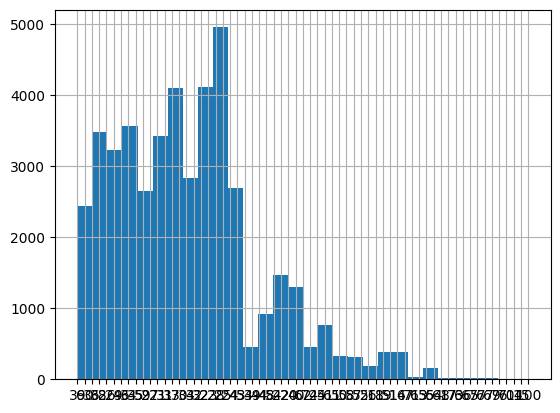

In [ ]:
data['Возраст'] = data['Пол, возраст'].apply(lambda x: x.split(',')[1].strip().split(' ')[0])#.unique()
data['Возраст'].hist(bins=30)

In [ ]:
# def get_sex(arg):
#     if 'Мужчина' in arg:
#         return 'М'
#     else:
#         return 'Ж'

data['Пол'] = data['Пол, возраст'].apply(
    lambda arg: 'М' if 'Мужчина' in arg else 'Ж'
)
data['Пол']

,Пол
0,М
1,М
2,Ж
3,М
4,Ж
...,...
44739,М
44740,М
44741,Ж
44742,М


In [ ]:
data['Пол'].value_counts()

,count
Пол,
М,36211
Ж,8533


In [ ]:
def get_age(arg):
    arg_splitted = arg.split(' ')
    year_words=['год', 'года', 'лет']
    for index, item in enumerate(arg_splitted):
        if item in year_words:
            return int(arg_splitted[index-1])

data['Возраст'] = data['Пол, возраст'].apply(get_age)
data['Возраст']

,Возраст
0,39
1,60
2,36
3,38
4,26
...,...
44739,30
44740,27
44741,48
44742,24


In [ ]:
data['Возраст'].mean(), data['Возраст'].median()

(np.float64(32.19674146254246), 31.0)

3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**.

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

В результате преобразования должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.

In [ ]:
data['Опыт работы'].iloc[128].split(' ')[:6]

['Опыт', 'работы', '5', 'лет', '6', 'месяцев']

In [ ]:
def get_experience(arg):
    if arg is np.nan or arg == 'Не указано':
        return None
    # ключевые слова
    year_words = ['год', 'года', 'лет']
    month_words = ['месяц', 'месяца', 'месяцев']

    arg_splitted = arg.split(' ')[:6]
    years = 0
    months = 0
    for index, item in enumerate(arg_splitted):
        if item in year_words:
            years = int(arg_splitted[index-1])
        if item in month_words:
            months = int(arg_splitted[index-1])
    return int(years*12 + months)

data['Опыт работы (месяц)'] = data['Опыт работы'].apply(get_experience)
# data = data.drop('Опыт работы', axis=1)
data['Опыт работы (месяц)'].median() / 12, data['Опыт работы (месяц)'].mean() / 12

(8.333333333333334, np.float64(9.534911981573712))

In [ ]:
data['Опыт работы'][2]

'Опыт работы 10 лет 3 месяца  Октябрь 2004 — Декабрь  2014 10 лет 3 месяца ПАО Сбербанк Кассир-операционист Работа с денежной наличностью, обслуживание клиентов, операции с иностранной валютой, проведение инкассации, составление и обработка первичных документов.'

<Axes: >

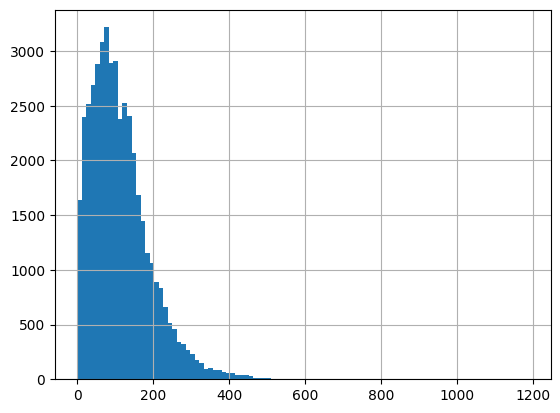

In [ ]:
data['Опыт работы (месяц)'].hist(bins=100)#, log=True)

In [ ]:
1200 / 12

100.0

In [ ]:
data[data['Опыт работы (месяц)'] >= 1000]

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто,Образование,Возраст,Пол,Опыт работы (месяц)
40015,"Мужчина , 48 лет , родился 27 января 1971",60000 руб.,Системный администратор Windows,"Ростов-на-Дону , готов к переезду , готов к командировкам","частичная занятость, полная занятость","гибкий график, полный день, вахтовый метод, удаленная работа","Опыт работы 99 лет Июнь 1920 — по настоящее время 99 лет АО ТК Горизонт Ростовская область , www.gorizontmall.ru Услуги для населения ... Центры развлечения Начальник отдела информационных технол...",АО ТК Горизонт,Начальник отдела информационных технологий,"Высшее образование 2014 Московский технологический институт, Москва Профпереподготовка, Сетевое администрирования (CISCO Discovery), Системный администратор (специализация MS Windows) 1999 Москов...",2019-04-16 08:09:00,Не указано,высшее,48,М,1188.0


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов миллионников:
    
   <code> million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    
    
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , …
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
>Совет: структура текста может меняться в зависимости от указания ближайшего метро.


In [ ]:
sorted(data['Город, переезд, командировки'].apply(lambda x: x.split(',')[2].strip()).unique())

['Абакан',
 'Австралия',
 'Австралия)',
 'Австрия',
 'Адлер',
 'Азербайджан',
 'Аксай (Ростовская область))',
 'Актау',
 'Актау)',
 'Александров',
 'Алматы',
 'Алтайский край',
 'Алушта',
 'Альметьевск)',
 'Амурск',
 'Амурская область',
 'Анапа',
 'Ангарск)',
 'Армавир',
 'Артем)',
 'Астана)',
 'Астраханская область',
 'Астрахань)',
 'Атырау',
 'Атырау)',
 'Балабаново',
 'Балашиха)',
 'Барановичи)',
 'Барнаул)',
 'Батайск)',
 'Белгород',
 'Белгород)',
 'Белгородская область)',
 'Белоусово)',
 'Бельгия',
 'Благовещенск (Амурская область)',
 'Благовещенск (Амурская область))',
 'Болгария',
 'Боровск',
 'Брест)',
 'Брянск',
 'Брянская область',
 'Бузулук',
 'Великий Новгород',
 'Великий Новгород)',
 'Великобритания',
 'Венгрия',
 'Венесуэла',
 'Видное',
 'Витебск',
 'Владивосток',
 'Владивосток)',
 'Волгоград',
 'Волгоградская область',
 'Волжский)',
 'Вологда)',
 'Воронеж',
 'Воронеж)',
 'Воронежская область',
 'Воронежская область)',
 'Воротынск)',
 'Всеволожск',
 'Всеволожск)',
 'Вьетн

In [ ]:
def get_city(arg):
    million_cities = [
        'Новосибирск', 'Екатеринбург', 'Нижний Новгород',
        'Казань', 'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону',
        'Уфа', 'Красноярск', 'Пермь', 'Воронеж', 'Волгоград'
    ]
    city = arg.split(',')[0].strip()
    if (city == 'Москва') or (city == 'Санкт-Петербург'):
        return city
    elif city in million_cities:
        return 'город миллионник'
    else:
        return 'другие'
data['Город'] = data['Город, переезд, командировки'].apply(get_city)
data['Город'].value_counts()

,count
Город,
Москва,16621
другие,15854
город миллионник,7332
Санкт-Петербург,4937


In [ ]:
data['Город, переезд, командировки'].iloc[0]

'Советск (Калининградская область) , не готов к переезду , не готов к командировкам'

In [ ]:
'готов к переезду' in 'Королев , не готов к переезду , готов к редким командировкам'

True

In [ ]:
def get_ready_to_move(arg):
    if ('не готов к переезду' in arg) or ('не готова к переезду' in arg):
        return False
    # elif 'хочу' in arg:
    #     return True
    else:
        return True

data['Готовность к переезду'] = data['Город, переезд, командировки'].apply(get_ready_to_move)
data['Готовность к переезду'].value_counts(normalize=True)

,proportion
Готовность к переезду,
False,0.641851
True,0.358149


In [ ]:
data[~data['Город, переезд, командировки'].apply(lambda x: 'переезд' in x or 'переехать' in x)]

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто,Образование,Возраст,Пол,Опыт работы (месяц),Город,Готовность к переезду


In [ ]:
data[~data['Город, переезд, командировки'].apply(lambda x: 'командировк' in x)].iloc[0]['Город, переезд, командировки']

'Туапсе , готов к переезду (Абхазия, Колумбия, Венесуэла, Чехия, Бельгия, Великобритания, США, Швеция, Греция, Германия, Дания, Турция, Израиль, Финляндия, Испания, Франция, Италия, Сингапур, Аргентина, Швейцария, Кипр, Канада, Исландия, Япония, Бангладеш,'

In [ ]:
def get_ready_for_bisiness_trips(arg):
    if ('командировка' in arg):
        if ('не готов к командировкам' in arg) or ('не готова к командировкам' in arg):
            return False
        else:
            return True
    else:
        return False

data['Готовность к командировкам'] = data['Город, переезд, командировки'].apply(get_ready_for_bisiness_trips)
# data = data.drop('Город, переезд, командировки', axis=1)
data['Готовность к командировкам'].value_counts()

,count
Готовность к командировкам,
True,31640
False,13104


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:

![](https://i.imgur.com/mtimFxh.png)

Выполним данное преобразование для признаков "Занятость" и "График".

In [ ]:
set(data['Занятость'].apply(lambda x: x.split(',')).sum())

{' волонтерство',
 ' полная занятость',
 ' проектная работа',
 ' стажировка',
 ' частичная занятость',
 'волонтерство',
 'полная занятость',
 'проектная работа',
 'стажировка',
 'частичная занятость'}

In [ ]:
set(data['График'].apply(lambda x: x.split(',')).sum())

{' вахтовый метод',
 ' гибкий график',
 ' полный день',
 ' сменный график',
 ' удаленная работа',
 'вахтовый метод',
 'гибкий график',
 'полный день',
 'сменный график',
 'удаленная работа'}

In [ ]:
# get_dummies из pandas

In [ ]:
employments = ['полная занятость', 'частичная занятость',
              'проектная работа', 'волонтерство', 'стажировка']

charts = ['полный день', 'сменный график',
         'гибкий график', 'удаленная работа',
         'вахтовый метод']

for employment, chart in zip(employments, charts):
    # print(employment, chart)
    data[employment] = data['Занятость'].apply(lambda x: employment in x)
    data[chart] = data['График'].apply(lambda x: chart in x)

# data = data.drop('Занятость', axis=1)
# data = data.drop('График', axis=1)
data.head(1)

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто,Образование,Возраст,Пол,Опыт работы (месяц),Город,Готовность к переезду,Готовность к командировкам,полная занятость,полный день,частичная занятость,сменный график,проектная работа,гибкий график,волонтерство,удаленная работа,стажировка,вахтовый метод
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к переезду , не готов к командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, вахтовый метод, удаленная работа","Опыт работы 16 лет 10 месяцев Август 2010 — по настоящее время 8 лет 10 месяцев МАОУ ""СОШ № 1 г.Немана"" Системный администратор Обслуживание ПК,установка ПО, ремонт, периферийной техники, Интерне...","МАОУ ""СОШ № 1 г.Немана""",Системный администратор,"Неоконченное высшее образование 2000 Балтийская государственная академия рыбопромыслового флота, Калининград судоводительский, Организация и безопасность движения",2019-04-16 15:59:00,Имеется собственный автомобиль,неоконченное высшее,39,М,202.0,другие,False,False,True,True,True,True,True,True,False,True,False,True


6. Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**.
В чем беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019 (и прочитали в переменную `rates`).

В таблице `rates` нас будут интересовать столбцы:
* `currency` - наименование валюты в ISO кодировке,
* `date` - дата,
* `proportion` - пропорция,
* `close` - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед нами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуемся этой информацией в преобразованиях!

<img src="https://drive.google.com/uc?export=view&id=1pv25-wNijfAENySHbyNe9oCjGk4VbKgU" width="700">


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

In [ ]:
rates['date'] = pd.to_datetime(rates['date'])
print(rates['date'].min(), rates['date'].max())
rates['currency'].unique()

2017-12-29 00:00:00 2019-12-11 00:00:00


array(['USD', 'EUR', 'KZT', 'KGS', 'BYN', 'UAH', 'UZS', 'AZN'],
      dtype=object)

**Итак, финальный алгоритм преобразования:**
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [ ]:
data['ЗП'].apply(lambda x: x.split(' ')[1]).unique()

array(['руб.', 'бел.руб.', 'KZT', 'EUR', 'USD', 'грн.', 'сум', 'KGS',
       'AZN'], dtype=object)

In [ ]:
# def get_salary_num(arg):
#     salary = float(arg.split(' ')[0])
#     return salary

def get_salary_сurrency(arg):
    currency_dict = {
        'USD': 'USD', 'KZT': 'KZT',
        'грн': 'UAH', 'белруб': 'BYN',
        'EUR': 'EUR', 'KGS': 'KGS',
        'сум': 'UZS', 'AZN': 'AZN',
        'руб': 'RUB'
    }
    curr = arg.split(' ')[1].replace('.', '')
    return currency_dict[curr]

data['ЗП (tmp)'] = data['ЗП'].apply(lambda x: float(x.split(' ')[0]))
data['Курс (tmp)'] = data['ЗП'].apply(get_salary_сurrency)

In [ ]:
# rates['date'] = pd.to_datetime(rates['date']).dt.date
# data['Обновление резюме'] = pd.to_datetime(data['Обновление резюме']).dt.date

merged = data.merge(
    rates,
    left_on=['Курс (tmp)', 'Обновление резюме'],
    right_on=['currency', 'date',],
    how='left'
)
merged.head(3)

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто,Образование,Возраст,Пол,Опыт работы (месяц),Город,Готовность к переезду,Готовность к командировкам,полная занятость,полный день,частичная занятость,сменный график,проектная работа,гибкий график,волонтерство,удаленная работа,стажировка,вахтовый метод,ЗП (tmp),Курс (tmp),currency,per,date,time,close,vol,proportion
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к переезду , не готов к командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, вахтовый метод, удаленная работа","Опыт работы 16 лет 10 месяцев Август 2010 — по настоящее время 8 лет 10 месяцев МАОУ ""СОШ № 1 г.Немана"" Системный администратор Обслуживание ПК,установка ПО, ремонт, периферийной техники, Интерне...","МАОУ ""СОШ № 1 г.Немана""",Системный администратор,"Неоконченное высшее образование 2000 Балтийская государственная академия рыбопромыслового флота, Калининград судоводительский, Организация и безопасность движения",2019-04-16 15:59:00,Имеется собственный автомобиль,неоконченное высшее,39,М,202.0,другие,False,False,True,True,True,True,True,True,False,True,False,True,29000.0,RUB,NaN,NaN,NaT,NaN,NaN,NaN,NaN
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, удаленная работа","Опыт работы 19 лет 5 месяцев Январь 2000 — по настоящее время 19 лет 5 месяцев Временный трудовой коллектив Москва Информационные технологии, системная интеграция, интернет ... Разработка програм...",Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель","Высшее образование 1981 Военно-космическая академия им. А.Ф. Можайского, Санкт-Петербург АСУ, АСУ",2019-04-12 08:42:00,Не указано,высшее,60,М,233.0,другие,False,True,True,True,True,True,True,True,False,True,False,False,40000.0,RUB,NaN,NaN,NaT,NaN,NaN,NaN,NaN
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к командировкам",полная занятость,полный день,"Опыт работы 10 лет 3 месяца Октябрь 2004 — Декабрь 2014 10 лет 3 месяца ПАО Сбербанк Кассир-операционист Работа с денежной наличностью, обслуживание клиентов, операции с иностранной валютой, про...",ПАО Сбербанк,Кассир-операционист,"Среднее специальное образование 2002 Профессиональный лицей 39 г. Твери Экономический, Банковское дело",2019-04-16 08:35:00,Не указано,среднее специальное,36,Ж,123.0,другие,False,False,True,True,False,False,False,False,False,False,False,False,20000.0,RUB,NaN,NaN,NaT,NaN,NaN,NaN,NaN


In [ ]:
merged['close'] = merged['close'].fillna(1)
merged['proportion'] = merged['proportion'].fillna(1)
data['ЗП (руб)'] = merged['close'] * merged['ЗП (tmp)'] / merged['proportion']
data = data.drop(['ЗП', 'ЗП (tmp)', 'Курс (tmp)'], axis=1)

In [ ]:
data['ЗП (руб)'].median() / 1000, data['ЗП (руб)'].mean() / 1000

(60.0, np.float64(80.0046342079385))

In [ ]:
data.to_csv('hh_database_preprocessed.csv', index=False)

## 3. Исследование зависимостей в данных

1. Построим распределение признака **"Возраст"**. При описании распределения можно ориентироваться на следующие вопросы:
* чему равна мода распределения,
* каковы предельные значения признака,
* в каком примерном интервале находится возраст большинства соискателей,
* есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?

> Совет: построим гистограмму и коробчатую диаграмму рядом.

In [ ]:
fig = px.histogram(
    data_frame=data,
    x='Возраст',
    title='Распределение возраста соискателей',
    histnorm='percent',
    width=500,
    marginal='box',
)
fig.show()

***

**Вывод:**

*Из представленного распределения возраста видно, что модальным значением является возраст 30 лет, возраст соискателей лежит в интервале от 14 до 100 лет. Основная масса соискателей в возрасте от 27 до 36 лет (могут быть другие примерные границы, близкие к указанным). Из формы распределения можно увидеть потенциальные аномалии - в данных есть соискатели подозрительно "преклонного" возраста: 100 летний пользователь сайта hh.ru + подозрение вызывают 14-летние соискатели.*

***

2. Построим распределение признака **"Опыт работы (месяц)"**. В выводе можно опираться на следующие вопросы:
* чему равна мода распределения,
* каковы предельные значения признака,
* в каком примерном интервале находится опыт работы большинства соискателей,
* есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?

In [ ]:
fig = px.histogram(
    data_frame=data,
    x='Опыт работы (месяц)',
    title='Распределение опыта работы соискателей',
    histnorm='percent',
    width=500,
    marginal='box',
)
fig.show()

***

**Вывод:**

*Из представленного распределения опыта работы видно, что модальное значение опыта находится в интервале от 80 до 84 месяцев, возраст соискателей лежит в интервале от 0 до 1188 месяцев. Основная масса соискателей имеет опыт работы от 57 до 154 лет. Из графика можно увидеть потенциальные аномалии - в данных есть соискатель, опыт работы которого почти 100 лет (1188 месяцев), что является невозможным. А также по форме распределение очень похоже на полученное в предыдущем пункте для возраста! Но связь этих двух признаков мы ещё проверим далее...*

***

3. Построим распределение признака **"ЗП (руб)"**. Контрольные вопросы для вывода:
* каковы предельные значения признака,
* в каком примерном интервале находится заработная плата большинства соискателей,
* есть ли аномалии для признака возраста,
* обратите внимание на гигантские размеры желаемой заработной платы.


In [ ]:
fig = px.histogram(
    data_frame=data,
    x='ЗП (руб)',
    title='Распределение желаемой з/п соискателей',
    histnorm='percent',
    width=10000,
    marginal='box'
)
fig.show()

***

**Вывод:**

*Из представленного распределения заработной платы видно, что желаемая з/п варьируется лежит от 1 до 24 миллионов рублей. Основная масса соискателей желает оплату от 37 до 95 тысяч. Из графиков отчливо видны аномальные значения, из-за которых сильно искажено распределения - заработные платы выше 1 млн рублей.*

***

4. Построим диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используем для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.

На что обратить внимание в выводе:
* для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы?
* как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?

In [ ]:
bar_data = data[data['ЗП (руб)'] < 1e6].groupby('Образование', as_index=False)['ЗП (руб)'].median()
fig = px.bar(
    data_frame=bar_data,
    x='Образование',
    y='ЗП (руб)',
    title='Медианная з/п по уровню образования'
)
fig.show()

***

**Вывод:**

*Из построенной диаграммы видно, что наибольшую заработную плату запрашивают люди с высшим образованием, наименьшую - соискатели со средним и средним специальным. Так как показатель заработной платы различен в каждой из категории, то признак явно оказывает влияние на целевой показатель*

***

5. Построим диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используем для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.

Вопросы для вывода:
* как соотносятся медианные уровни желаемой заработной платы и их размах в городах?
* как вы считаете, важен ли признак города при прогнозировании заработной платы?

In [ ]:
box_data = data[data['ЗП (руб)']<1e6]
fig = px.box(
    data_frame=box_data,
    x='Город',
    y='ЗП (руб)',
    color='Город',
    title='Распределение з/п по городам'
)
fig.show()

***

**Вывод:**

*Из диаграммы видно,что наибольшая медианная заработная плата в Москве (85к), но в ней же наблюдается и наибольший размах зарплат, далее идет Санкт-Петербург (медиана - 41к), а последнее место делят города миллионники и "другие" (медиана - 40к). Интересен момент, что максимальная заработная плата в Москве и категории "другие" практически совпадает (900к и 923к).*

***

6. Построим **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируем график, сравнив уровень заработной платы в категориях.

In [ ]:
bar_data = data.groupby(
    ['Готовность к командировкам', 'Готовность к переезду'],
    as_index=False
)['ЗП (руб)'].median()

fig = px.bar(
    data_frame=bar_data,
    y='Готовность к переезду',
    x='ЗП (руб)',
    barmode="group",
    color='Готовность к командировкам',
    orientation='h',
    title='Медианная з/п по готовности к командировкам/переезду'
)
fig.show()

***

**Вывод:**

*Из диаграммы видно,что готовность к переезду и командировкам сильно повышает уровень заработной платы. Наиболее высокие заработные платы у людей, готовых к переезду и командировкам. Наименьшая - у не готовых к тому и другому. Вероятно это связано с тем, что командируемые - это, как правило, люди занимающие высокие должности, поэтому такая связь вполне объяснима.*

***

7. Построим сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице построим **тепловую карту** и проанализируем её, сравнив показатели внутри групп.

In [ ]:
pivot = box_data.pivot_table(
    index='Образование',
    columns='Возраст',
    values='ЗП (руб)',
    aggfunc='median',
    fill_value=0
)
pivot

In [ ]:
fig = px.imshow(
    pivot,
    aspect='auto',
    color_continuous_scale='greens',
    title='Медианная з/п по образованию и возрасту'
)
fig.show()

***

**Вывод:**

*Из тепловой карты можно понять, что для категорий "среднее специальное" и "среднее" образование медианная заработная плата слабо растет с увеличением возраста, в отличие от высшего образования и неоконченного высшего. Для категории "высшее" наблюдаются большие значения заработной платы для возраста 16 и 17 лет, однако это может быть связано с тем, что соискателей в данной категории возраста очень мало и они имеют высокий уровень желаемой з/п. Далее для соискателей с высшим образованием наблюдается четкая тенденция: с увеличением возраста увеличивается медианная з/п, можно сказать, что для данной группы наблюдается карьерный рост.*

***

8. Построим **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведём из месяцев в года, чтобы признаки были в едином масштабе.

Также для наглядности построим на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100): она соответствует значениям, когда опыт работы равен возрасту человека; соответственно, точки, лежащие на этой прямой и выше нее - аномалии в данных (опыт работы больше либо равен возрасту соискателя).

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(10, 5))
scatter_data = data.copy()
scatter_data['Опыт работы (год)'] = scatter_data['Опыт работы (месяц)']/12
sns.lineplot(x=[0, 100], y=[0, 100])
sns.scatterplot(
    data=scatter_data,
    x='Возраст',
    y='Опыт работы (год)',
    alpha=0.1
)
plt.title('Зависимость опыта работы от возраста');
print(scatter_data[scatter_data['Опыт работы (год)']>= scatter_data['Возраст']].shape)

***

**Вывод:**

*Из представленной диаграммы рассеяния наблюдается прямая зависимость опыта работы от возраста, что вполне логично: чем старше соискатель, тем больше его опыт работы. Точки лежащие на прямой и находящиеся выше нее - аномальные значения опыта работы, равного или превышающего возраст соискателя. Таких наблюдений в данных в общей сложности 7 штук.*

***

## 4. Очистка данных

1. Начнем с дубликатов в наших данных. Найдём **полные дубликаты** в таблице с резюме и удалим их.

In [ ]:
duplicates = data[data.duplicated()]
print(duplicates.shape[0])

data = data.drop_duplicates()

2. Займемся пропусками. Выведем информацию **о числе пропусков** в столбцах.

In [ ]:
np.nan * 8 + 10

In [ ]:
null_data = data.isnull().sum()
display(null_data[null_data > 0])

3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалим строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполним **медианным** значением.

In [ ]:
data = data.dropna(subset=['Последнее/нынешнее место работы', 'Последняя/нынешняя должность'])
data['Опыт работы (месяц)'] = data['Опыт работы (месяц)'].fillna(data['Опыт работы (месяц)'].median())
print(round(data['Опыт работы (месяц)'].mean()))

4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалим резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [ ]:
outliers = data[(data['ЗП (руб)'] > 1e6) | (data['ЗП (руб)'] < 1e3)]
data = data.drop(outliers.index)
print(outliers.shape[0])

5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдём такие резюме и удалим их из данных.

In [ ]:
outliers = data[data['Опыт работы (месяц)']/12 >= data['Возраст']]
data = data.drop(outliers.index)
print(outliers.shape[0])

# Успехов!